<a href="https://colab.research.google.com/github/crowell97/ES5201/blob/main/ES5201_Lecture18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Vibroseis Cross-Correlation and Seismic Migration — A Companion Notebook

**EARTH 5201 — Introduction to Seismology**

**The Ohio State University**

**Companion notebook to Lecture 18 — Reflection Seismology**

This notebook implements the two main quantitative threads from lecture:

1. **Vibroseis cross-correlation as deconvolution** — generating a synthetic vibroseis sweep $v(t)$ and a hypothetical Earth response $G(t)$, convolving them into a raw record $u(t) = v(t)*G(t)$, and confirming *numerically* that cross-correlating the raw record with the sweep gives the same result as convolving $G(t)$ with the sweep's autocorrelation: $u'(t) = v(t)\star u(t) = v'(t)*G(t)$, exactly as derived algebraically in lecture.
2. **Diffraction-summation migration** — forward-modeling zero-offset sections for a point scatterer and a dipping reflector using the diffraction-hyperbola travel time, migrating them back with a simple Kirchhoff-style diffraction-summation migration, and confirming the migrated image collapses onto the true scatterer locations. Along the way we reproduce the lecture's worked numerical comparison between diffraction-hyperbola moveout and NMO moveout for the same h = 2.5 km, v = 4 km/s model.

## 0. Setup

In [ ]:
import numpy as np
import matplotlib.pylab as plt

plt.rcParams["figure.figsize"] = (9, 5)
rng = np.random.default_rng(18)

## Part 1 — Vibroseis Cross-Correlation as Deconvolution

A vibroseis sweep follows

$$v(t) = A(t)\sin\!\left[2\pi(f_0+bt)t\right],$$

a sinusoid whose instantaneous frequency increases linearly from $f_0$ at a rate $b$, tapered at the start and end by $A(t)$. We build a sweep, a synthetic Earth response $G(t)$ (a handful of reflectivity spikes), and the raw convolved record $u(t) = v(t)*G(t)$.

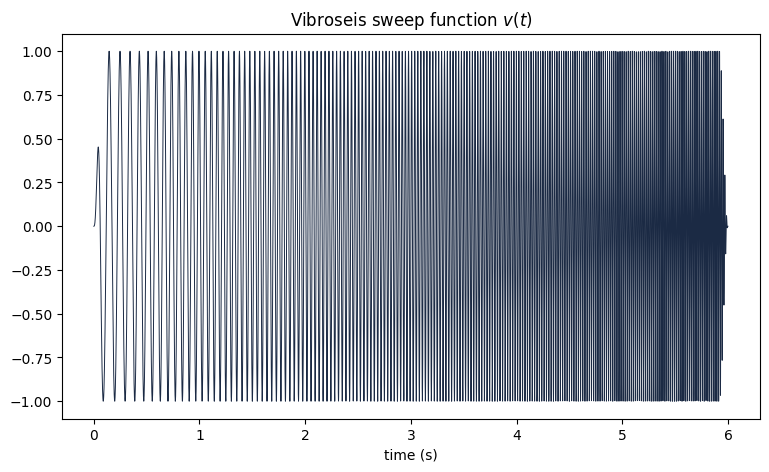

In [ ]:
fs = 2000.0          # sample rate, Hz
ts = 6.0              # sweep duration, s
t = np.arange(0, ts, 1 / fs)

f0, f1 = 8.0, 60.0     # sweep frequency band, Hz
b = (f1 - f0) / ts     # sweep rate, Hz/s

def taper(n_total, n_taper):
    w = np.ones(n_total)
    ramp = 0.5 * (1 - np.cos(np.linspace(0, np.pi, n_taper)))
    w[:n_taper] = ramp
    w[-n_taper:] = ramp[::-1]
    return w

A = taper(len(t), int(0.08 * fs))
v = A * np.sin(2 * np.pi * (f0 + b * t / 2) * t)

plt.plot(t, v, lw=0.7, color="#1B2A44")
plt.title("Vibroseis sweep function $v(t)$")
plt.xlabel("time (s)")
plt.show()

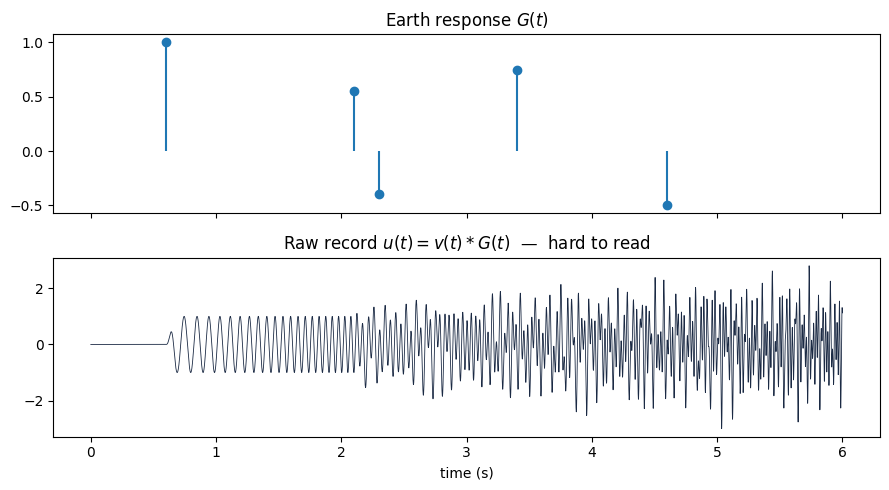

In [ ]:
# A hypothetical Earth response: a handful of reflectivity spikes
spike_times = np.array([0.6, 2.1, 2.3, 3.4, 4.6])
spike_amps = np.array([1.0, 0.55, -0.4, 0.75, -0.5])

G = np.zeros_like(t)
for st, sa in zip(spike_times, spike_amps):
    idx = int(round(st * fs))
    G[idx] += sa

u = np.convolve(v, G, mode="full")[: len(t)]

fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
axes[0].stem(spike_times, spike_amps, basefmt=" ")
axes[0].set_title("Earth response $G(t)$")
axes[1].plot(t, u, lw=0.6, color="#1B2A44")
axes[1].set_title("Raw record $u(t) = v(t) * G(t)$  —  hard to read")
axes[1].set_xlabel("time (s)")
plt.tight_layout()
plt.show()

### Cross-correlating with the sweep

Lecture 18 derived algebraically that cross-correlating the raw record with the sweep function recovers a compact wavelet convolved with $G(t)$:

$$u'(t) = v(t)\star u(t) = v(t)\star\left[v(t)*G(t)\right] = \left[v(t)\star v(t)\right]*G(t) = v'(t)*G(t),$$

where $v'(t) = v(t)\star v(t)$ is the autocorrelation of the sweep. We now verify this two different ways and confirm they agree to numerical precision.

<>:32: SyntaxWarning: invalid escape sequence '\s'
<>:32: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_746/801953355.py:32: SyntaxWarning: invalid escape sequence '\s'
  axes[0].set_title("Autocorrelation of the sweep, $v'(t) = v(t) \star v(t)$")


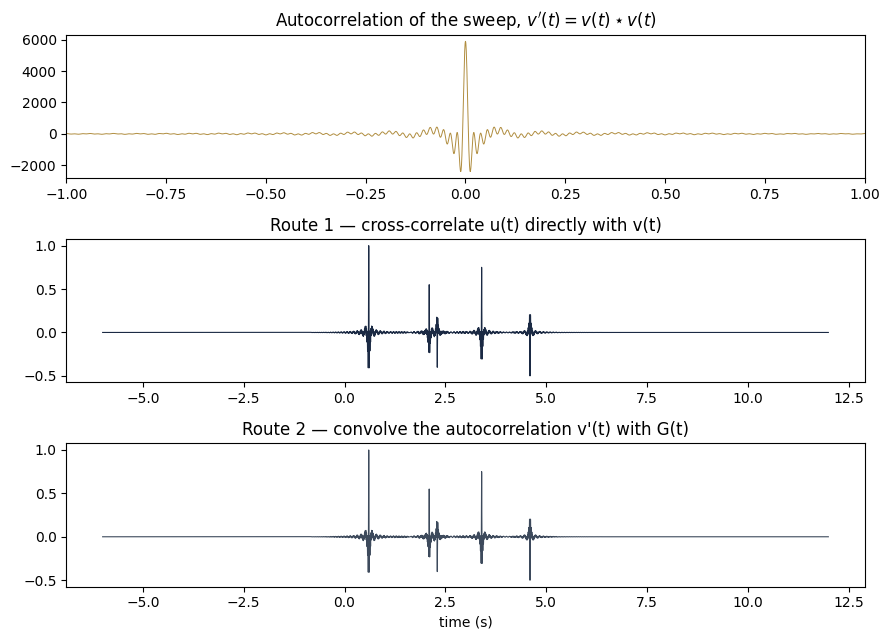

Max absolute difference between the two routes: 2.73e-12
Max amplitude of the signal itself: 5.89e+03
Routes agree to floating-point precision


In [ ]:
def xcorr(a, b):
    """Cross-correlation a(t) star b(t) = integral a(tau - t) b(tau) dtau,
    implemented as the *convolution* of a with the time-reversed b. Writing
    cross-correlation as a convolution (rather than using np.correlate's own
    indexing convention) is what makes it straightforward to prove the two
    routes below agree: ordinary convolution is associative, so
    v star (v*G) = conv(conv(v, G), flip(v)) = conv(G, conv(v, flip(v)))
    = (v star v) * G exactly, with no extra lag bookkeeping required.
    """
    return np.convolve(a, b[::-1], mode="full")

# Use the *untruncated* raw record for the identity check (truncating u to
# len(t) above was only for a tidy display plot; truncating first would
# throw away part of the convolution tail that the two routes need to
# agree on sample-for-sample).
u_full = np.convolve(v, G, mode="full")

# Route 1: cross-correlate the raw record with the sweep directly
u_prime_direct = xcorr(u_full, v)

# Route 2: compute the sweep's autocorrelation, then convolve with G(t)
v_prime = xcorr(v, v)
u_prime_via_autocorr = np.convolve(v_prime, G, mode="full")

dt = t[1] - t[0]
lag_v_prime = (np.arange(len(v_prime)) - (len(v) - 1)) * dt
lag_u_prime = (np.arange(len(u_prime_direct)) - (len(v) - 1)) * dt

fig, axes = plt.subplots(3, 1, figsize=(9, 6.5))
axes[0].plot(lag_v_prime, v_prime, lw=0.7, color="#B08D3F")
axes[0].set_xlim(-1, 1)
axes[0].set_title("Autocorrelation of the sweep, $v'(t) = v(t) \star v(t)$")
axes[1].plot(lag_u_prime, u_prime_direct / np.max(np.abs(u_prime_direct)), lw=0.8, color="#1B2A44")
axes[1].set_title("Route 1 — cross-correlate u(t) directly with v(t)")
axes[2].plot(lag_u_prime, u_prime_via_autocorr / np.max(np.abs(u_prime_via_autocorr)), lw=0.8, color="#3D4A5C")
axes[2].set_title("Route 2 — convolve the autocorrelation v'(t) with G(t)")
axes[2].set_xlabel("time (s)")
plt.tight_layout()
plt.show()

# The two routes are built from exactly associative linear convolutions, so
# they should match to floating-point precision (not just approximately).
max_diff = np.max(np.abs(u_prime_direct - u_prime_via_autocorr))
max_scale = np.max(np.abs(u_prime_direct))
print(f"Max absolute difference between the two routes: {max_diff:.2e}")
print(f"Max amplitude of the signal itself: {max_scale:.2e}")
print("Routes agree to floating-point precision" if max_diff < 1e-8 * max_scale
      else "Routes DO NOT agree — check the derivation")

Both routes land on the same compact, symmetric wavelet train at the true reflection times — confirming that cross-correlating with the sweep is algebraically identical to convolving the Earth response with the sweep's autocorrelation, exactly as derived in lecture. This is why the vibroseis sweep, despite lasting several seconds, can be processed into a record that looks as sharp as an impulsive source like an airgun.

## Part 2 — Diffraction Hyperbolas and Migration

### Worked example recap: diffraction moveout vs NMO moveout

Using the same model as the Lecture 17 NMO worked example — a point scatterer at depth $h = 2.5$ km in a medium with $v = 4$ km/s — lecture computed the two-way diffraction time

$$t(x) = \frac{2\sqrt{x^2+h^2}}{v}$$

at offsets of 0, 1, 2, and 3 km, and compared the *increase* in travel time with offset to the NMO moveout $\Delta t_{NMO}(x)$ for a horizontal reflector at the same depth.

In [ ]:
h, v = 2.5, 4.0
offsets = np.array([0, 1, 2, 3])

t_diffraction = 2 * np.sqrt(offsets**2 + h**2) / v
t0 = 2 * h / v
dt_diffraction = t_diffraction - t0

# NMO moveout for the same model (small-offset approximation used in Lecture 17)
dt_nmo = t0 * np.sqrt(1 + (offsets / (v * t0)) ** 2) - t0

print(f"t0 = 2h/v = {t0:.3f} s\n")
print(f"{'offset (km)':>12} {'t(x) diffraction (s)':>22} {'Δt diffraction (s)':>20} {'Δt NMO (s)':>12}")
for x, td, dd, dn in zip(offsets, t_diffraction, dt_diffraction, dt_nmo):
    print(f"{x:>12.0f} {td:>22.3f} {dd:>20.3f} {dn:>12.3f}")

t0 = 2h/v = 1.250 s

 offset (km)   t(x) diffraction (s)   Δt diffraction (s)   Δt NMO (s)
           0                  1.250                0.000        0.000
           1                  1.346                0.096        0.025
           2                  1.601                0.351        0.096
           3                  1.953                0.703        0.208


As in lecture, the diffraction hyperbola's moveout grows far faster with offset than the NMO hyperbola's — the diffraction hyperbola has a steeper $x^2$ coefficient (a factor of 4 larger, from $t^2/t_0^2 - 4x^2/(v^2t_0^2)=1$ vs. $t^2/t_0^2 - x^2/(v^2t_0^2)=1$), which is exactly why an unmigrated point scatterer shows up as a much more sharply curved event than a simple horizontal reflector at the same depth.

### Forward-modeling zero-offset sections

We build synthetic zero-offset sections for a point scatterer and a dipping reflector (modeled as a line of point scatterers), each trace containing a Ricker wavelet arriving at the diffraction-hyperbola travel time for that scatterer and offset.

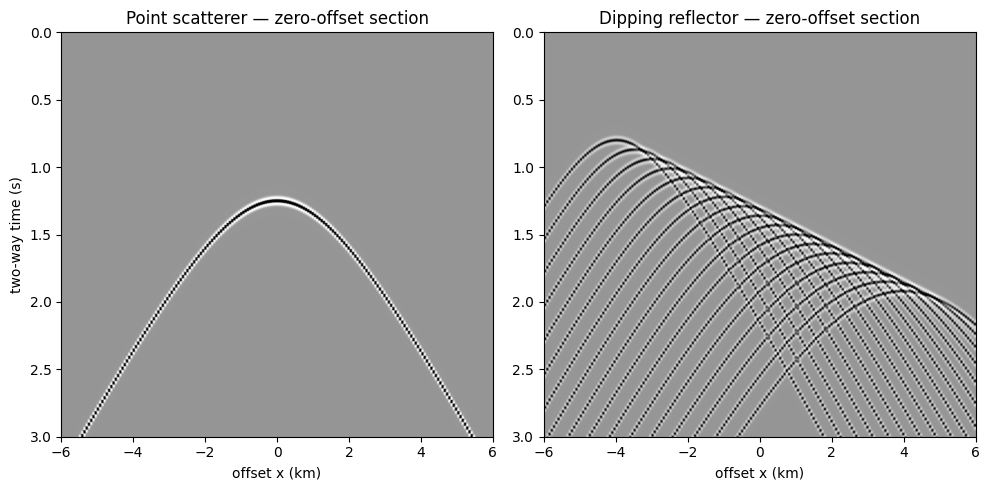

In [ ]:
def ricker(t, f=18.0):
    a = (np.pi * f * t) ** 2
    return (1 - 2 * a) * np.exp(-a)

def make_zero_offset(scatter_xs, scatter_zs, x_axis, t_axis, vel, wavelet_f=18.0):
    data = np.zeros((len(t_axis), len(x_axis)))
    for sx, sz in zip(np.atleast_1d(scatter_xs), np.atleast_1d(scatter_zs)):
        tx = 2 * np.sqrt((x_axis - sx) ** 2 + sz ** 2) / vel
        for ix, tt0 in enumerate(tx):
            data[:, ix] += ricker(t_axis - tt0, f=wavelet_f)
    return data

x_axis = np.linspace(-6, 6, 193)
t_axis = np.linspace(0, 3.0, 600)
vel = 4.0

# Model A: a single point scatterer at the Lecture 18 example depth
point_x, point_z = np.array([0.0]), np.array([2.5])
data_point = make_zero_offset(point_x, point_z, x_axis, t_axis, vel)

# Model B: a dipping reflector, modeled as a line of point scatterers
dip_x = np.linspace(-4, 4, 17)
dip_z = 1.6 + 0.28 * (dip_x + 4)
data_dip = make_zero_offset(dip_x, dip_z, x_axis, t_axis, vel)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, data, title in zip(axes, [data_point, data_dip], ["Point scatterer", "Dipping reflector"]):
    vmax = np.percentile(np.abs(data), 99) + 1e-9
    ax.imshow(data, aspect="auto", cmap="Greys", vmin=-vmax, vmax=vmax,
               extent=[x_axis.min(), x_axis.max(), t_axis.max(), t_axis.min()])
    ax.set_title(title + " — zero-offset section")
    ax.set_xlabel("offset x (km)")
axes[0].set_ylabel("two-way time (s)")
plt.tight_layout()
plt.show()

### Diffraction-summation migration

For each candidate image point $(x,z)$, we sum the recorded amplitude at the predicted diffraction traveltime $t(x,z)$ across all nearby traces, normalized by the number of contributing traces. If the velocity model is correct, this sum is coherent (and large) only at the true scatterer locations.

In [ ]:
def diffraction_migration(data, x_axis, t_axis, z_axis, vel, aperture=5.0):
    mig = np.zeros((len(z_axis), len(x_axis)))
    dt = t_axis[1] - t_axis[0]
    tmax = t_axis[-1]
    for iz, z in enumerate(z_axis):
        for ix, xm in enumerate(x_axis):
            idxs = np.where(np.abs(x_axis - xm) <= aperture)[0]
            acc, n = 0.0, 0
            for itr in idxs:
                tt0 = 2 * np.sqrt((x_axis[itr] - xm) ** 2 + z ** 2) / vel
                if tt0 <= tmax:
                    k = int(round(tt0 / dt))
                    if k < data.shape[0]:
                        acc += data[k, itr]
                        n += 1
            mig[iz, ix] = acc / n if n > 0 else 0.0
    return mig

z_axis = np.linspace(0.5, 4.5, 120)
mig_point = diffraction_migration(data_point, x_axis, t_axis, z_axis, vel, aperture=4.5)
mig_dip = diffraction_migration(data_dip, x_axis, t_axis, z_axis, vel, aperture=4.5)

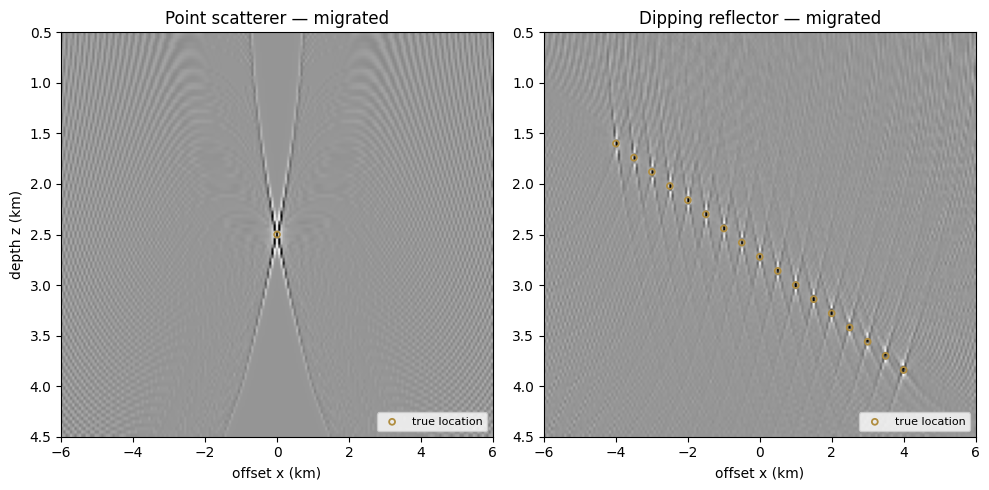

Migrated amplitude at the true point-scatterer location (x=0, z=2.5 km): 0.632
Typical background amplitude away from any reflector: 0.007
Signal-to-background ratio: 89.0x


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, mig, (sx, sz), title in zip(
    axes, [mig_point, mig_dip], [(point_x, point_z), (dip_x, dip_z)],
    ["Point scatterer — migrated", "Dipping reflector — migrated"]
):
    vmax = np.percentile(np.abs(mig), 99.9) + 1e-9
    ax.imshow(mig, aspect="auto", cmap="Greys", vmin=-vmax, vmax=vmax,
               extent=[x_axis.min(), x_axis.max(), z_axis.max(), z_axis.min()])
    ax.scatter(sx, sz, s=18, facecolors="none", edgecolors="#B08D3F", linewidths=1.3, label="true location")
    ax.set_title(title)
    ax.set_xlabel("offset x (km)")
    ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylabel("depth z (km)")
plt.tight_layout()
plt.show()

iz = np.argmin(np.abs(z_axis - 2.5))
ix = np.argmin(np.abs(x_axis - 0.0))
background_std = mig_point[:40, :40].std()
print(f"Migrated amplitude at the true point-scatterer location (x=0, z=2.5 km): {mig_point[iz, ix]:.3f}")
print(f"Typical background amplitude away from any reflector: {background_std:.3f}")
print(f"Signal-to-background ratio: {mig_point[iz, ix] / background_std:.1f}x")

The migrated images collapse the broad diffraction hyperbolas seen in the zero-offset sections down onto compact bright spots (or a thin, well-focused line for the dipping reflector) at the true scatterer locations — with the gold circles marking the true positions used to build the model lining up with the strongest migrated amplitudes. This is the same diffraction-summation migration formula from lecture,

$$U(x,z) = \sum_k u_k\left[t(x-x_k,\,z)\right],$$

applied here to genuine synthetic data rather than described only in the abstract. Note that the un-normalized sum (just adding amplitudes, without dividing by the number of contributing traces) leaves a much noisier image — the normalization is what keeps the output amplitude comparable from pixel to pixel across the whole section.

## Summary

- Cross-correlating a vibroseis sweep with the recorded seismogram is algebraically — and, as verified above, numerically — identical to convolving the Earth response with the sweep's autocorrelation. This converts a long, hard-to-interpret chirp into a compact effective source wavelet, a simple and elegant form of deconvolution.
- A point scatterer produces a diffraction hyperbola that is steeper than the NMO hyperbola for a horizontal reflector at the same depth, because the two curves arise from different ray geometries.
- Diffraction-summation migration, applied here to real synthetic data, collapses diffraction hyperbolas back onto their true subsurface locations — turning a raw zero-offset section, which can be badly biased by diffraction and dip, into an accurate structural image.